# A 1D diffusion model 

Here we develop a one-dimensional numerical model of diffusion. 
It assumes a constant diffusivity.
It uses a regular grid.
It has a step functions for an initial profile. 
It has fixed boundary conditions. 

The diffusion equation:

$$ \frac{\partial z}{\partial t} = D\frac{\partial^2 z}{\partial x^2} $$

Here $z$ is elevation, $t$ is time, $x$ is the spatial dimension, and $D$ is a transport-rate coefficient, sometimes called hillslope diffusivity---with dimensions length squared per time.

The discretised version of the diffusion equation we'll solve with our model is: 

$$ z^{t+1}_x = z^t_x + {D \Delta t \over \Delta x^2} (z^t_{x+1} - 2z^t_x + z^t_{x-1}) $$

This is the FTCS (Forward Time Centred in Space) scheme that you can look up in a textbook.

We'll use two libraryes, NumPy (for arrays) and Matplotlib (for plots), that aren't pard of the core Python distribution. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Start by setting two fixed model parameters---the diffusivity and the size of the model domain. 

In [4]:
D  = 100 # diffusivity
Lx = 300 # model domain

Next, set up the grid using a NumPy array.

In [5]:
dx = 0.5 # grid spacing
x = np.arange(start=0, stop=Lx, step=dx)
nx = len(x) # number of grid nodes

Set the initial conditions for the model.
The elevation $z$ is a step function with a high value to the left, a low value on the right, and a cliff in the middle of the domain.

In [10]:
z = np.zeros_like(x)
z_left = 500
z_right = 0
z[x <= Lx / 2] = z_left
z[x > Lx / 2] = z_right

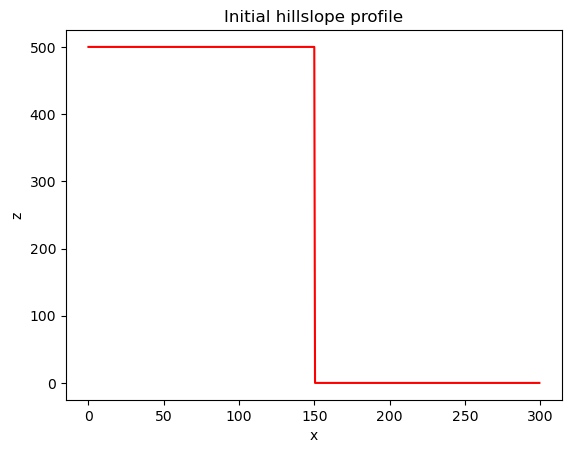

In [14]:
plt.figure() # Set up a figure window
plt.plot(x, z, "r") 
plt.xlabel("x")
plt.ylabel("z")
plt.title("Initial hillslope profile")
plt.show()

Set up time stepping for the model.
Calculate a stable time step from a stability criterion.

In [15]:
nt = 5000 # number of time steps
dt = 0.5 * dx**2 / D # time step

Loop over the time steps of the model, solving the diffusion equation using the FTCS scheme decribed above.
Note the use of array operations on the elevation $z$. 
The boundary conditions remain fixed in each time step. 

In [19]:
for t in range(0, nt):
	z[1:-1] += D * dt / dx ** 2 * (z[:-2] - 2*z[1:-1] + z[2:])

Plot the result.

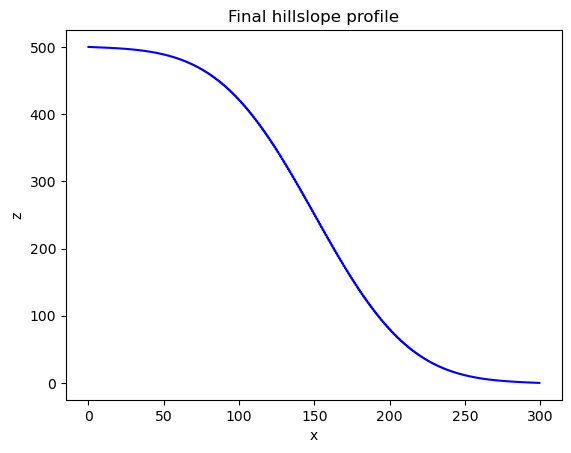

In [20]:
plt.figure() 
plt.plot(x, z, "b") 
plt.xlabel("x")
plt.ylabel("z")
plt.title("Final hillslope profile")
plt.show()